# MLnode House Prices Training Notebook

A tabular **regression** demo — the smallest end-to-end mlnode pipeline:
1. **Define** a 3-layer MLP as JSON
2. **Validate** tensor shapes statically
3. **Build** an executable `nn.Module`
4. **Train** on the California Housing dataset to predict median house value
5. **Evaluate** with RMSE, MAE and R²

The data pipeline needs one extra package: `pip install scikit-learn`

In [1]:
# Install MLnode (run once)
# !pip install -e /path/to/mlnode
# Or if already installed:
from mlnode import MLnodeModel
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import time

torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Device: cpu
PyTorch: 2.12.0+cu130


## 1. Define the Model as JSON

A plain feed-forward regressor — 8 features in, one price out:

```
Input (8,)
  → Linear(8→64) → ReLU
  → Linear(64→32) → ReLU
  → Linear(32→1)                → (1,) predicted price
```

No softmax, no argmax: the final `Linear` emits a raw scalar and the loss is MSE.

In [2]:
model_json = "house_prices_mlp.mlnode.json"

## 2. Validate Shapes Statically

In [3]:
# Parse and validate — no GPU memory allocated
model = MLnodeModel.load(model_json)
result = model.validate()

print(f"Valid: {result.valid}")
print(f"\nShape propagation through the graph:")
for node_id, shape in result.node_shapes.items():
    print(f"  {node_id:10s} → {shape}")

if not result.valid:
    print(f"\nErrors:")
    for err in result.errors:
        print(f"  {err.message}")

Valid: True

Shape propagation through the graph:
  input_0    → ('B', 8)
  fc1        → ('B', 64)
  relu1      → ('B', 64)
  fc2        → ('B', 32)
  relu2      → ('B', 32)
  price      → ('B', 1)


## 3. Build the PyTorch Module

In [4]:
# Compile to nn.Module and move to device
module = model.build().to(device)

# Verify with a dummy batch
dummy = torch.randn(4, 8, device=device)
out = module(dummy)
print(f"Input shape:  {dummy.shape}")
print(f"Output shape: {out.shape}")
print(f"Parameters:   {sum(p.numel() for p in module.parameters()):,}")
print(f"\nModule structure:")
print(module)

Input shape:  torch.Size([4, 8])
Output shape: torch.Size([4, 1])
Parameters:   2,689

Module structure:
MLnodeModule(
  (_layers): ModuleDict(
    (fc1): Linear(in_features=8, out_features=64, bias=True)
    (relu1): ReLU()
    (fc2): Linear(in_features=64, out_features=32, bias=True)
    (relu2): ReLU()
    (price): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 4. Data Pipeline

**California Housing** — 20,640 census block groups from the 1990 census. Eight numeric
features per block (median income, house age, average rooms, location, …) and the target is
the block's median house value in units of $100,000, capped at $500,001.

Scaling matters here: `Population` runs into the thousands while `AveBedrms` hovers near 1.
Feed those in raw and the first `Linear` sees wildly different gradient magnitudes per feature.

In [5]:
housing = fetch_california_housing(data_home="./data", download_if_missing=True)
X = housing.data.astype(np.float32)
y = housing.target.astype(np.float32)

print(f"Samples:  {X.shape[0]:,}")
print(f"Features: {X.shape[1]} — {', '.join(housing.feature_names)}")
print(f"Target:   ${y.min() * 100_000:,.0f} – ${y.max() * 100_000:,.0f}  (mean ${y.mean() * 100_000:,.0f})")

# Split before scaling, so test statistics never leak into training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features using training statistics only
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# Targets kept as (N, 1) to match the model's output shape — no silent broadcasting
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).unsqueeze(1))
test_ds = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test).unsqueeze(1))

BATCH_SIZE = 256

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=1024, shuffle=False)

print(f"\nTraining samples: {len(train_ds):,}")
print(f"Test samples:     {len(test_ds):,}")
print(f"Batch size:       {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")

# Verify a batch
features, targets = next(iter(train_loader))
print(f"\nBatch features: {features.shape}")
print(f"Batch targets:  {targets.shape}")

Samples:  20,640
Features: 8 — MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude
Target:   $14,999 – $500,001  (mean $206,856)

Training samples: 16,512
Test samples:     4,128
Batch size:       256
Training batches: 65

Batch features: torch.Size([256, 8])
Batch targets:  torch.Size([256, 1])


## 5. Training Loop

In [6]:
# Hyperparameters
EPOCHS = 40
LEARNING_RATE = 1e-3

# Optimizer and loss — MSE instead of CrossEntropy, because this is regression
optimizer = optim.Adam(module.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()

# Learning rate scheduler — reduce on plateau
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

print(f"Optimizer:     Adam (lr={LEARNING_RATE})")
print(f"Loss:          MSELoss")
print(f"Epochs:        {EPOCHS}")
print(f"LR Scheduler:  ReduceLROnPlateau (patience=3, factor=0.5)")

Optimizer:     Adam (lr=0.001)
Loss:          MSELoss
Epochs:        40
LR Scheduler:  ReduceLROnPlateau (patience=3, factor=0.5)


In [7]:
def train_epoch(module, loader, optimizer, criterion, device):
    module.train()
    running_loss = 0.0
    total = 0

    for features, targets in loader:
        features, targets = features.to(device), targets.to(device)

        # Forward pass through the MLnode-built module
        preds = module(features)
        loss = criterion(preds, targets)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * features.size(0)
        total += features.size(0)

    return running_loss / total


@torch.no_grad()
def evaluate(module, loader, criterion, device):
    module.eval()
    running_loss = 0.0
    total = 0
    all_preds, all_targets = [], []

    for features, targets in loader:
        features, targets = features.to(device), targets.to(device)
        preds = module(features)

        running_loss += criterion(preds, targets).item() * features.size(0)
        total += features.size(0)
        all_preds.append(preds.cpu())
        all_targets.append(targets.cpu())

    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)

    mse = running_loss / total
    mae = (all_preds - all_targets).abs().mean().item()

    # R² — fraction of variance explained; 0.0 means "no better than predicting the mean"
    ss_res = ((all_targets - all_preds) ** 2).sum()
    ss_tot = ((all_targets - all_targets.mean()) ** 2).sum()
    r2 = (1 - ss_res / ss_tot).item()

    return mse, mae, r2

In [8]:
# Training loop
history = {"train_mse": [], "test_mse": [], "test_mae": [], "test_r2": []}

print("=" * 68)
print(f"Training House Prices MLP ({sum(p.numel() for p in module.parameters()):,} params)")
print("=" * 68)

start = time.time()

for epoch in range(1, EPOCHS + 1):
    train_mse = train_epoch(module, train_loader, optimizer, criterion, device)
    test_mse, test_mae, test_r2 = evaluate(module, test_loader, criterion, device)

    scheduler.step(test_mse)

    history["train_mse"].append(train_mse)
    history["test_mse"].append(test_mse)
    history["test_mae"].append(test_mae)
    history["test_r2"].append(test_r2)

    if epoch == 1 or epoch % 5 == 0:
        print(f"  Epoch {epoch:>2}/{EPOCHS}  "
              f"train MSE: {train_mse:.4f}  test MSE: {test_mse:.4f}  "
              f"RMSE: ${test_mse ** 0.5 * 100_000:>7,.0f}  R²: {test_r2:.3f}")

elapsed = time.time() - start

print("=" * 68)
print(f"Trained in {elapsed:.1f}s")
print(f"  Test RMSE: ${history['test_mse'][-1] ** 0.5 * 100_000:,.0f}")
print(f"  Test MAE:  ${history['test_mae'][-1] * 100_000:,.0f}")
print(f"  Test R²:   {history['test_r2'][-1]:.3f}")
print("=" * 68)

Training House Prices MLP (2,689 params)


  Epoch  1/40  train MSE: 3.0278  test MSE: 1.2545  RMSE: $112,003  R²: 0.043


  Epoch  5/40  train MSE: 0.4579  test MSE: 0.4501  RMSE: $ 67,086  R²: 0.657


  Epoch 10/40  train MSE: 0.3764  test MSE: 0.3799  RMSE: $ 61,637  R²: 0.710


  Epoch 15/40  train MSE: 0.3503  test MSE: 0.3577  RMSE: $ 59,811  R²: 0.727


  Epoch 20/40  train MSE: 0.3358  test MSE: 0.3428  RMSE: $ 58,545  R²: 0.738


  Epoch 25/40  train MSE: 0.3227  test MSE: 0.3320  RMSE: $ 57,616  R²: 0.747


  Epoch 30/40  train MSE: 0.3119  test MSE: 0.3208  RMSE: $ 56,640  R²: 0.755


  Epoch 35/40  train MSE: 0.2966  test MSE: 0.3095  RMSE: $ 55,630  R²: 0.764


  Epoch 40/40  train MSE: 0.2905  test MSE: 0.3005  RMSE: $ 54,814  R²: 0.771
Trained in 7.7s
  Test RMSE: $54,814
  Test MAE:  $37,678
  Test R²:   0.771


## 6. Training Curves

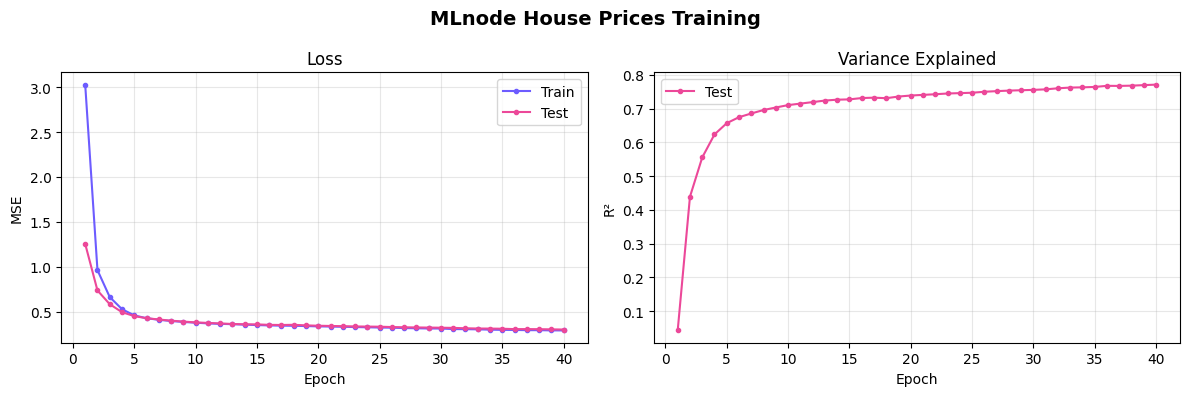

In [9]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

epochs_range = range(1, len(history["train_mse"]) + 1)

# Loss
ax1.plot(epochs_range, history["train_mse"], "o-", label="Train", color="#6d5cff", markersize=3)
ax1.plot(epochs_range, history["test_mse"], "o-", label="Test", color="#ec4899", markersize=3)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MSE")
ax1.set_title("Loss")
ax1.legend()
ax1.grid(alpha=0.3)

# R²
ax2.plot(epochs_range, history["test_r2"], "o-", label="Test", color="#ec4899", markersize=3)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("R²")
ax2.set_title("Variance Explained")
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle("MLnode House Prices Training", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Sample Predictions

Every point on the diagonal is a perfect prediction. The vertical stripe at $500k is the
dataset's cap — every block worth more was recorded at that ceiling, so the model has no
signal to separate them and simply spreads its guesses below the line.

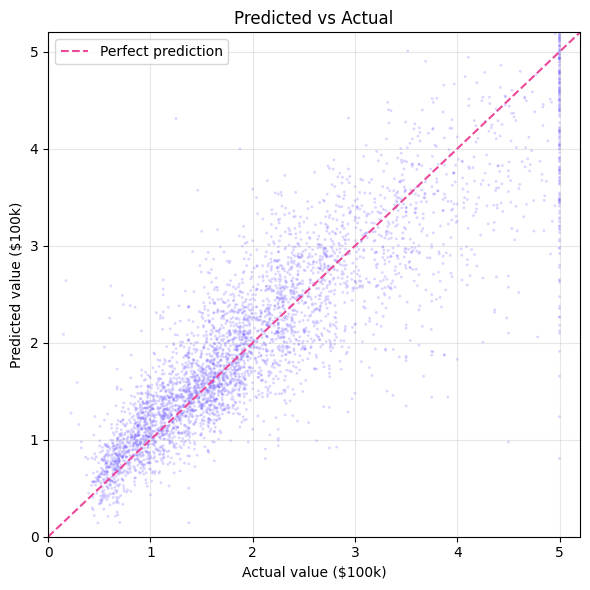

    Actual   Predicted       Error
----------------------------------
$   47,700  $   44,870  $   -2,830
$   45,800  $  123,844  $  +78,044
$  500,001  $  457,294  $  -42,707
$  218,600  $  253,032  $  +34,432
$  278,000  $  289,650  $  +11,650
$  158,700  $  172,573  $  +13,873
$  198,200  $  265,903  $  +67,703
$  157,500  $  157,906  $     +406
$  340,000  $  270,394  $  -69,606
$  446,600  $  454,247  $   +7,647


In [10]:
module.eval()
with torch.no_grad():
    preds = module(torch.from_numpy(X_test).to(device)).cpu().numpy().squeeze(1)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, preds, s=4, alpha=0.25, color="#6d5cff", edgecolors="none")
lims = [0, 5.2]
ax.plot(lims, lims, "--", color="#ec4899", linewidth=1.5, label="Perfect prediction")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual value ($100k)")
ax.set_ylabel("Predicted value ($100k)")
ax.set_title("Predicted vs Actual")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# A handful of individual predictions
print(f"{'Actual':>10}  {'Predicted':>10}  {'Error':>10}")
print("-" * 34)
for i in range(10):
    actual, pred = y_test[i] * 100_000, preds[i] * 100_000
    print(f"${actual:>9,.0f}  ${pred:>9,.0f}  ${pred - actual:>+9,.0f}")

## 8. Save the Model

In [11]:
# Save the MLnode architecture JSON
model.save("house_prices_mlp.mlnode.json")
print("Architecture saved to house_prices_mlp.mlnode.json")

# Save trained PyTorch weights
torch.save(module.state_dict(), "house_prices_mlp_weights.pth")
print("Weights saved to house_prices_mlp_weights.pth")

# To reload later:
# model = MLnodeModel.load("house_prices_mlp.mlnode.json")
# module = model.build()
# module.load_state_dict(torch.load("house_prices_mlp_weights.pth"))
#
# Note: the graph describes the network only. The StandardScaler fitted above is part of the
# data pipeline, so persist it alongside the weights (joblib.dump) if you plan to serve this.

Architecture saved to house_prices_mlp.mlnode.json
Weights saved to house_prices_mlp_weights.pth
